# 3주차 실습 — Hugging Face & Colab 온보딩
### 비전AI와비즈니스 | 경영대학 AI빅데이터융합경영학과

모델: `ZhengPeng7/BiRefNet` / 데이터: `agentic-learning-ai-lab/Walking-Tours-Semantic`

GPU 설정 → 첫 추론 → 내 이미지 → 공개 데이터 → 전이학습 → 학습 전후 평가 → 학습 곡선의 기존 순서를 유지합니다.

**오늘의 목표**
1. 사전학습 BiRefNet의 마지막 1채널 출력층을 **ADE20K 150개 클래스용 출력층**으로 교체한다.
2. 학습 없이 먼저 도로·건물·사람 등의 픽셀 라벨을 예측한다.
3. **같은 초기 모델**을 파인튜닝하고 같은 평가 이미지에서 학습 전후 mIoU와 색상 마스크를 비교한다.

**비교 기준**: Before = 사전학습 BiRefNet + 무작위로 초기화한 150채널 출력층.
After = 그 모델을 파인튜닝하여 검증 loss로 선택한 checkpoint.
원래 BiRefNet은 전경/배경 분할 모델이므로 라벨 이름만 바꿔서는 150종류를 구분할 수 없습니다.
여기서는 마지막 출력층을 실제로 바꾸며, 학습 전 성능은 원본 이진 분할 모델의 성능을 뜻하지 않습니다.

---
## 0. 시작 전 — Colab 런타임 설정

**런타임 → 런타임 유형 변경 → T4 GPU**를 선택하세요.
BiRefNet은 큰 Swin-L 기반 모델입니다. 실습에서는 입력을 256×256으로 줄이고,
배치 2와 gradient accumulation 8을 사용합니다. 모델 카드의 기본 추론 예제는 1024×1024입니다.
처음에는 모델 다운로드와 선택한 이미지 준비에 시간이 걸립니다.

In [1]:
# GPU 확인 — 표가 출력되면 GPU 정상 할당
!nvidia-smi

Mon Oct 12 02:22:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch
print("PyTorch 버전:", torch.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())
print("GPU 이름:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU만 사용 중")

PyTorch 버전: 2.11.0+cu130
GPU 사용 가능: True
GPU 이름: Tesla T4


---
## 1. 라이브러리 설치

`transformers`와 `Trainer`, BiRefNet이 사용하는 `timm`·`kornia`·`einops`,
이미지와 데이터셋을 다룰 라이브러리를 설치합니다.
Colab의 PyTorch와 torchvision은 함께 제공되는 버전을 사용합니다.
설치 후 이미 import한 라이브러리의 재시작 안내가 나오면 런타임을 다시 시작하고 위에서부터 실행하세요.

In [3]:
%pip install -q "transformers==4.57.6" "datasets==4.4.1" "accelerate>=1.0,<2" "timm==1.0.30" "kornia==0.8.3" "einops==0.8.2" "huggingface_hub>=0.34,<1" pillow matplotlib pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 59.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.6/511.6 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.0/201.0 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 40.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==

---
## 2. Hugging Face 둘러보기 (웹)

1. [BiRefNet 모델 카드](https://huggingface.co/ZhengPeng7/BiRefNet)에서 기본 이진 분할 추론 예제를 확인합니다.
2. [Walking-Tours-Semantic 데이터 카드](https://huggingface.co/datasets/agentic-learning-ai-lab/Walking-Tours-Semantic)에서 이미지·마스크와 영상별 split을 확인합니다.
3. [ADE20K 라벨 목록](https://huggingface.co/datasets/huggingface/label-files/blob/main/ade20k-id2label.json)에서 도로·건물·사람의 클래스 번호를 찾습니다.

WT-Sem의 정답은 ADE20K로 학습한 OpenSeeD가 만든 **pseudo label**입니다.
따라서 이번 점수는 사람이 검수한 정답과의 정확도가 아니라 제공된 pseudo label과의 일치도를 평가합니다.

---
## 3. 첫 번째 추론 — 의미 분할

BiRefNet은 일반적인 Hugging Face semantic segmentation 모델과 출력 구조·전처리가 달라
직접 전처리 → 모델 → `argmax` 함수를 연결합니다. 첫 추론이라는 기존 실습 단계는 동일합니다.

사전학습 특징 추출기와 decoder를 가져오고, 마지막 `Conv2d`만 1 → 150채널로 교체합니다.
이 단계에서는 학습하지 않습니다. 모든 픽셀은 150개 중 한 클래스로 예측됩니다.

In [4]:
import json
from pathlib import Path
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from huggingface_hub import HfApi, HfFileSystem, hf_hub_download
from transformers import AutoModelForImageSegmentation, PretrainedConfig, set_seed
from torchvision import transforms
from PIL import Image
from IPython.display import display

checkpoint = "ZhengPeng7/BiRefNet"
dataset_id = "agentic-learning-ai-lab/Walking-Tours-Semantic"
# 확인한 코드·데이터 revision으로 고정합니다.
MODEL_REVISION = "e2bf8e4460fc8fa32bba5ea4d94b3233d367b0e4"
DATASET_REVISION = "92974cc1896d27f29d3d873154f3fc97be53a928"
SEED, IMAGE_SIZE, IGNORE_INDEX = 42, 256, 255
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 이 JSON의 내용도 고정해 매 실행에서 같은 클래스 순서를 사용합니다.
id2label = {int(k): v.strip() for k, v in json.loads('{\n  "0": "wall",\n  "1": "building",\n  "2": "sky",\n  "3": "floor",\n  "4": "tree",\n  "5": "ceiling",\n  "6": "road",\n  "7": "bed ",\n  "8": "windowpane",\n  "9": "grass",\n  "10": "cabinet",\n  "11": "sidewalk",\n  "12": "person",\n  "13": "earth",\n  "14": "door",\n  "15": "table",\n  "16": "mountain",\n  "17": "plant",\n  "18": "curtain",\n  "19": "chair",\n  "20": "car",\n  "21": "water",\n  "22": "painting",\n  "23": "sofa",\n  "24": "shelf",\n  "25": "house",\n  "26": "sea",\n  "27": "mirror",\n  "28": "rug",\n  "29": "field",\n  "30": "armchair",\n  "31": "seat",\n  "32": "fence",\n  "33": "desk",\n  "34": "rock",\n  "35": "wardrobe",\n  "36": "lamp",\n  "37": "bathtub",\n  "38": "railing",\n  "39": "cushion",\n  "40": "base",\n  "41": "box",\n  "42": "column",\n  "43": "signboard",\n  "44": "chest of drawers",\n  "45": "counter",\n  "46": "sand",\n  "47": "sink",\n  "48": "skyscraper",\n  "49": "fireplace",\n  "50": "refrigerator",\n  "51": "grandstand",\n  "52": "path",\n  "53": "stairs",\n  "54": "runway",\n  "55": "case",\n  "56": "pool table",\n  "57": "pillow",\n  "58": "screen door",\n  "59": "stairway",\n  "60": "river",\n  "61": "bridge",\n  "62": "bookcase",\n  "63": "blind",\n  "64": "coffee table",\n  "65": "toilet",\n  "66": "flower",\n  "67": "book",\n  "68": "hill",\n  "69": "bench",\n  "70": "countertop",\n  "71": "stove",\n  "72": "palm",\n  "73": "kitchen island",\n  "74": "computer",\n  "75": "swivel chair",\n  "76": "boat",\n  "77": "bar",\n  "78": "arcade machine",\n  "79": "hovel",\n  "80": "bus",\n  "81": "towel",\n  "82": "light",\n  "83": "truck",\n  "84": "tower",\n  "85": "chandelier",\n  "86": "awning",\n  "87": "streetlight",\n  "88": "booth",\n  "89": "television receiver",\n  "90": "airplane",\n  "91": "dirt track",\n  "92": "apparel",\n  "93": "pole",\n  "94": "land",\n  "95": "bannister",\n  "96": "escalator",\n  "97": "ottoman",\n  "98": "bottle",\n  "99": "buffet",\n  "100": "poster",\n  "101": "stage",\n  "102": "van",\n  "103": "ship",\n  "104": "fountain",\n  "105": "conveyer belt",\n  "106": "canopy",\n  "107": "washer",\n  "108": "plaything",\n  "109": "swimming pool",\n  "110": "stool",\n  "111": "barrel",\n  "112": "basket",\n  "113": "waterfall",\n  "114": "tent",\n  "115": "bag",\n  "116": "minibike",\n  "117": "cradle",\n  "118": "oven",\n  "119": "ball",\n  "120": "food",\n  "121": "step",\n  "122": "tank",\n  "123": "trade name",\n  "124": "microwave",\n  "125": "pot",\n  "126": "animal",\n  "127": "bicycle",\n  "128": "lake",\n  "129": "dishwasher",\n  "130": "screen",\n  "131": "blanket",\n  "132": "sculpture",\n  "133": "hood",\n  "134": "sconce",\n  "135": "vase",\n  "136": "traffic light",\n  "137": "tray",\n  "138": "ashcan",\n  "139": "fan",\n  "140": "pier",\n  "141": "crt screen",\n  "142": "plate",\n  "143": "monitor",\n  "144": "bulletin board",\n  "145": "shower",\n  "146": "radiator",\n  "147": "glass",\n  "148": "clock",\n  "149": "flag"\n}\n').items()}

labels = [id2label[i] for i in range(150)]
label2id = {name: i for i, name in id2label.items()}
NUM_CLASSES = len(labels)
assert set(id2label) == set(range(150))

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# trust_remote_code는 해당 revision의 BiRefNet 구현을 가져오는 데 필요합니다.
base_model = AutoModelForImageSegmentation.from_pretrained(
    checkpoint, revision=MODEL_REVISION, trust_remote_code=True, dtype=torch.float32,
)
old_head = base_model.decoder.conv_out1[0]
assert isinstance(old_head, nn.Conv2d) and old_head.out_channels == 1
original_out_channels = old_head.out_channels
# 새 출력층 초기화는 노트북 전체에서 이 한 번만 수행합니다.
set_seed(SEED)
base_model.decoder.conv_out1[0] = nn.Conv2d(
    old_head.in_channels, NUM_CLASSES, kernel_size=old_head.kernel_size,
    stride=old_head.stride, padding=old_head.padding, dilation=old_head.dilation,
    groups=old_head.groups, bias=old_head.bias is not None,
)
del old_head

class SemanticBiRefNet(nn.Module):
    def __init__(self, network):
        super().__init__()
        self.network = network
        self.config = PretrainedConfig(
            num_labels=NUM_CLASSES, id2label=id2label, label2id=label2id,
        )

    def forward(self, pixel_values, labels=None):
        output = self.network(pixel_values)
        # 고정한 BiRefNet revision은 train/eval 시 반환 구조가 다릅니다.
        if self.network.training:
            scaled = output[0]
            masks = scaled[1] if self.network.config.out_ref else scaled
            logits = masks[-1]
        else:
            logits = output[-1]
        if logits.shape[1] != NUM_CLASSES:
            raise RuntimeError(f"출력 채널 오류: {logits.shape}")
        result = {"logits": logits}
        if labels is not None:
            if logits.shape[-2:] != labels.shape[-2:]:
                logits = F.interpolate(logits, size=labels.shape[-2:], mode="bilinear", align_corners=False)
                result["logits"] = logits
            # 다중 클래스이므로 sigmoid/BCE가 아닌 최종 logits의 cross entropy.
            result["loss"] = F.cross_entropy(logits, labels.long(), ignore_index=IGNORE_INDEX)
        return result

model = SemanticBiRefNet(base_model).to(device)
del base_model  # model.network가 같은 모델을 계속 소유합니다.

@torch.inference_mode()
def segment(image, network=None, *, original_size=True):
    network = model if network is None else network
    network.eval()
    model_device = next(network.parameters()).device
    pixels = image_transform(image.convert("RGB")).unsqueeze(0).to(model_device)
    logits = network(pixel_values=pixels)["logits"]
    prediction = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
    if original_size and prediction.shape != (image.height, image.width):
        # 큰 업로드 사진에 150채널 logits를 확대하면 메모리를 많이 사용합니다.
        # 예측 ID 마스크만 nearest로 확대하며, 평가 해상도는 256×256입니다.
        prediction = np.asarray(Image.fromarray(prediction).resize(image.size, Image.Resampling.NEAREST))
    return prediction

print("출력층:", original_out_channels, "→", model.network.decoder.conv_out1[0].out_channels)
print("입력 크기:", IMAGE_SIZE, "×", IMAGE_SIZE, "/ 장치:", device)
print("예: road=", label2id["road"], ", building=", label2id["building"], ", person=", label2id["person"])

config.json:   0%|          | 0.00/405 [00:00<?, ?B/s]

BiRefNet_config.py:   0%|          | 0.00/298 [00:00<?, ?B/s]

birefnet.py: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/444M [00:00<?, ?B/s]

출력층: 1 → 150
입력 크기: 256 × 256 / 장치: cuda
예: road= 6 , building= 1 , person= 12


train/Amsterdam:   0%|          | 0/3 [00:00<?, ?it/s]

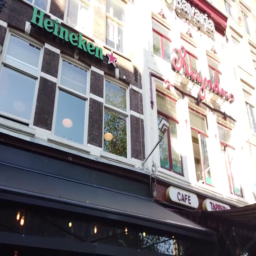

In [5]:
import io
import zipfile
from tqdm.auto import tqdm
from datasets import Dataset, DatasetDict, concatenate_datasets
from datasets import Image as DatasetImage

fs = HfFileSystem(token=False)
remote_root = f"datasets/{dataset_id}@{DATASET_REVISION}"
CACHE_DIR = Path("./walking-tours-cache") / DATASET_REVISION[:12] / str(IMAGE_SIZE)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_CITIES = ["Amsterdam", "Bangkok", "Chiang_Mai", "Istanbul", "Kuala_Lampur",
                "Singapore", "Stockholm", "Venice", "Wildlife", "Zurich"]

def zip_members(archive):
    names = [x.filename for x in archive.infolist() if not x.is_dir()
             and not x.filename.startswith("__MACOSX/")
             and Path(x.filename).suffix.lower() in {".png", ".jpg", ".jpeg"}]
    mapping = {Path(name).stem: name for name in names}
    if len(mapping) != len(names):
        raise ValueError("ZIP 내 중복 프레임 이름이 있습니다.")
    return mapping

def check_mask(mask):
    values = np.asarray(mask)
    if values.ndim != 2:
        raise ValueError("색상 시각화 마스크가 아닌 정수 ID 마스크가 필요합니다.")
    valid = ((values >= 0) & (values < NUM_CLASSES)) | (values == IGNORE_INDEX)
    if not np.all(valid):
        raise ValueError(f"지원하지 않는 마스크 ID: {np.unique(values[~valid])}")
    return values

def load_city(split, city, count, seed=SEED):
    folder = CACHE_DIR / split / city
    folder.mkdir(parents=True, exist_ok=True)
    manifest = folder / f"selection-{count}-{seed}.json"
    if manifest.exists():
        rows = json.loads(manifest.read_text(encoding="utf-8"))
        if all(Path(r["image"]).exists() and Path(r["mask"]).exists() for r in rows):
            return Dataset.from_list(rows).cast_column("image", DatasetImage()).cast_column("mask", DatasetImage())
    rows = []
    # Range request로 ZIP 목차와 선택한 파일만 읽습니다. 전체 30GB를 다운로드하지 않습니다.
    image_path = f"{remote_root}/images/{split}/{city}.zip"
    mask_path = f"{remote_root}/labels/{split}/{city}.zip"
    with fs.open(image_path, "rb", block_size=1024*1024) as image_file, \
         fs.open(mask_path, "rb", block_size=1024*1024) as mask_file, \
         zipfile.ZipFile(image_file) as iz, zipfile.ZipFile(mask_file) as mz:
        images, masks = zip_members(iz), zip_members(mz)
        if set(images) != set(masks):
            raise ValueError(f"{city}: 이미지와 마스크의 프레임 이름이 일치하지 않습니다.")
        keys = sorted(images)
        if not 0 < count <= len(keys):
            raise ValueError(f"{city}: 요청 {count}장, 실제 {len(keys)}장")
        # 영상 전체를 count개 시간 구간으로 나누고 각 구간에서 1장씩 고릅니다.
        edges = np.linspace(0, len(keys), count+1, dtype=int)
        rng = np.random.default_rng(seed)
        selected = [keys[rng.integers(edges[i], edges[i+1])] for i in range(count)]
        for key in tqdm(selected, desc=f"{split}/{city}"):
            image_local, mask_local = folder / f"{key}-image.png", folder / f"{key}-mask.png"
            if not (image_local.exists() and mask_local.exists()):
                with Image.open(io.BytesIO(iz.read(images[key]))) as im, \
                     Image.open(io.BytesIO(mz.read(masks[key]))) as mask:
                    if im.size != mask.size:
                        raise ValueError(f"{city}/{key}: 이미지·마스크 크기가 다릅니다.")
                    check_mask(mask)
                    im.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR).save(image_local)
                    # 정수 라벨은 반드시 NEAREST. ID 0=wall도 유효한 클래스입니다.
                    mask.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.NEAREST).save(mask_local)
            rows.append({"image": str(image_local.resolve()), "mask": str(mask_local.resolve()),
                         "city": city, "frame_id": key, "sample_id": f"{split}/{city}/{key}"})
    manifest.write_text(json.dumps(rows, ensure_ascii=False, indent=2), encoding="utf-8")
    return Dataset.from_list(rows).cast_column("image", DatasetImage()).cast_column("mask", DatasetImage())

preview_ds = load_city("train", "Amsterdam", 3)
image = preview_ds[0]["image"].convert("RGB")
display(image)

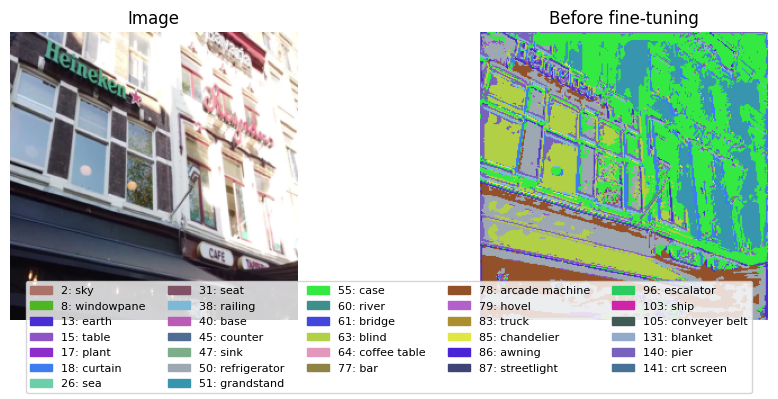

학습 전 예측 클래스: ['sky', 'windowpane', 'earth', 'table', 'plant', 'curtain', 'sea', 'seat', 'railing', 'base', 'counter', 'sink', 'refrigerator', 'grandstand', 'case', 'river', 'bridge', 'blind', 'coffee table', 'bar', 'arcade machine', 'hovel', 'truck', 'chandelier', 'awning', 'streetlight', 'escalator', 'ship', 'conveyer belt', 'blanket', 'pier', 'crt screen']


In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 클래스마다 고정된 색을 사용합니다. 같은 클래스는 학습 전후 같은 색입니다.
palette = np.random.default_rng(SEED).integers(35, 245, size=(256, 3), dtype=np.uint8)
palette[IGNORE_INDEX] = 0

def color_mask(mask):
    return palette[np.asarray(mask, dtype=np.uint8)]

def show_segmentation(image, prediction, target=None, title="Prediction"):
    panels = [("Image", image)]
    if target is not None:
        panels.append(("Provided label", color_mask(target)))
    panels.append((title, color_mask(prediction)))
    fig, axes = plt.subplots(1, len(panels), figsize=(5*len(panels), 4))
    for ax, (name, content) in zip(axes, panels):
        ax.imshow(content)
        ax.set_title(name)
        ax.axis("off")
    present = np.unique(target if target is not None else prediction)
    handles = [Patch(color=palette[int(i)]/255, label=f"{i}: {id2label[int(i)]}")
               for i in present if int(i) in id2label]
    if handles:
        fig.legend(handles=handles, loc="lower center", ncol=min(5, len(handles)), fontsize=8)
    fig.tight_layout(rect=(0, 0.15, 1, 1))
    plt.show()

prediction = segment(image)
show_segmentation(image, prediction, title="Before fine-tuning")
print("학습 전 예측 클래스:", [id2label[int(i)] for i in np.unique(prediction)])

**결과 해석**
- 이미지의 각 픽셀에 `0~149`의 클래스 번호를 예측하고, 고정된 색상으로 표시합니다.
- `road`, `building`, `person`은 각각 다른 클래스입니다. 사람 인스턴스별 구분은 하지 않습니다.
- 새 출력층은 아직 학습하지 않았으므로 의미 없는 마스크가 나와도 정상입니다.
- 추론에서는 `sigmoid`나 박스 임계값 대신 클래스 축의 `argmax`를 사용합니다.

---
## 4. 내 이미지로 바꿔보기

선택적으로 이미지를 업로드하여 학습 전 모델에 적용합니다.
업로드를 취소하면 앞의 예제 이미지를 사용합니다.

In [7]:
from google.colab import files
uploaded = files.upload()

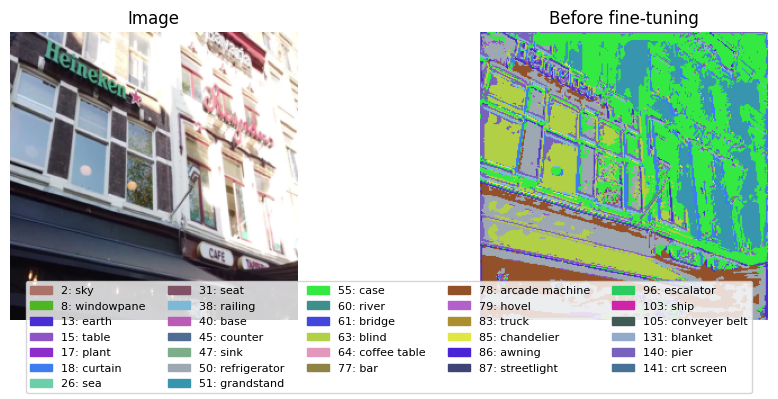

In [8]:
if uploaded:
    my_image = Image.open(io.BytesIO(next(iter(uploaded.values())))).convert("RGB")
else:
    my_image = image
my_prediction = segment(my_image)
show_segmentation(my_image, my_prediction, title="Before fine-tuning")

---
## 5. 공개 데이터셋 불러오기 (`datasets`)

WT-Sem은 train 10개 영상의 25,910프레임, val 3개 영상의 6,170프레임을 제공합니다.
저장소에는 이미지 ZIP과 라벨 ZIP이 따로 있어 프레임 이름으로 정확히 짝을 맞춥니다.
`load_dataset()`의 자동 변환 대신 ZIP에서 선택한 쌍만 읽고 `Dataset`으로 구성합니다.

마스크는 색상 이미지가 아닌 ADE20K **0부터 시작하는 클래스 ID**입니다.
예: `0=wall`, `1=building`, `2=sky`, `6=road`, `12=person`. ID 0을 배경으로 버리거나 1을 빼지 않습니다.
`255`가 있으면 loss와 평가에서 제외합니다.

In [9]:
ds = preview_ds
print(ds)
print("클래스 수:", NUM_CLASSES)
sample = ds[0]
print("마스크 ID:", np.unique(check_mask(sample["mask"])))
print("라벨 이름:", [id2label[int(i)] for i in np.unique(np.asarray(sample["mask"])) if int(i) in id2label])

Dataset({
    features: ['image', 'mask', 'city', 'frame_id', 'sample_id'],
    num_rows: 3
})
클래스 수: 150
마스크 ID: [  1  43  86  87 123]
라벨 이름: ['building', 'signboard', 'awning', 'streetlight', 'trade name']


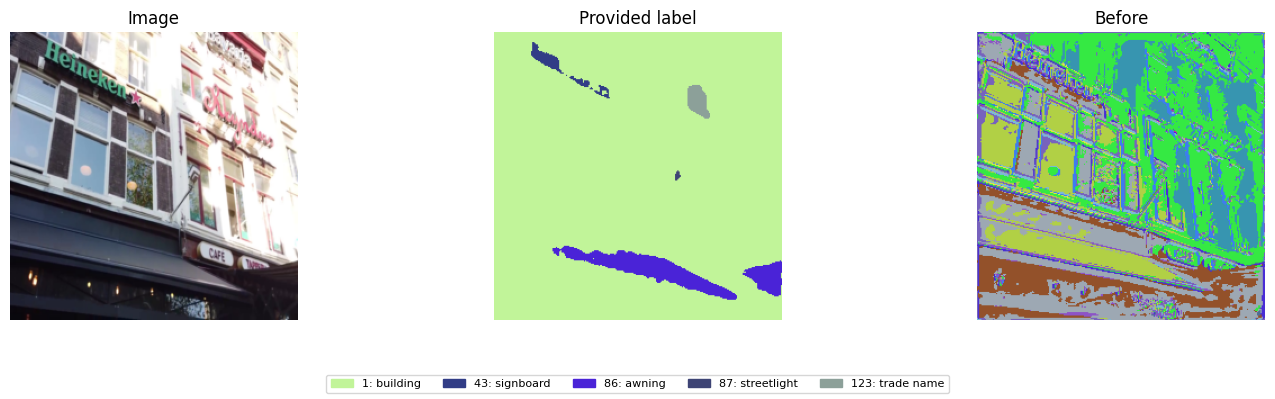

In [10]:
def ground_truth(sample):
    return check_mask(sample["mask"]).astype(np.int64)

sample = ds[0]
show_segmentation(sample["image"], segment(sample["image"]), ground_truth(sample), title="Before")

### 실습 (직접 해보기)

정답 마스크와 학습 전 예측을 비교하세요. 같은 위치의 픽셀이 같은 클래스로 예측되었는지 봅니다.
화면에 그려진 색 자체가 라벨 값은 아니며, 정수 ID 마스크를 사용해 학습·평가합니다.

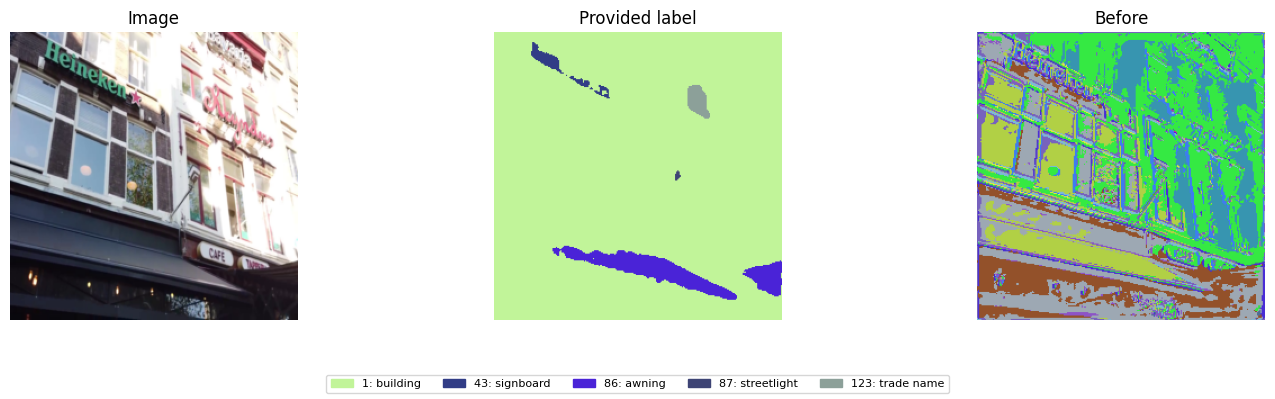

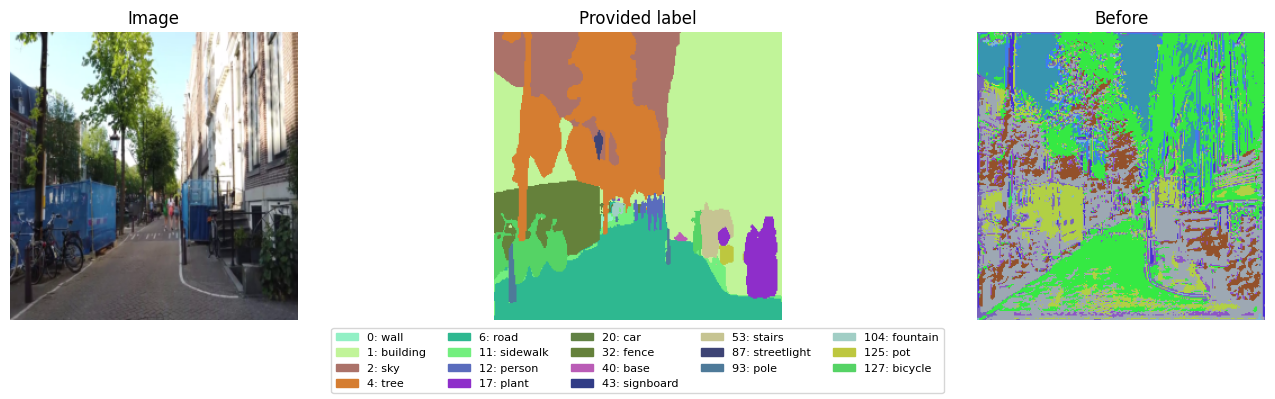

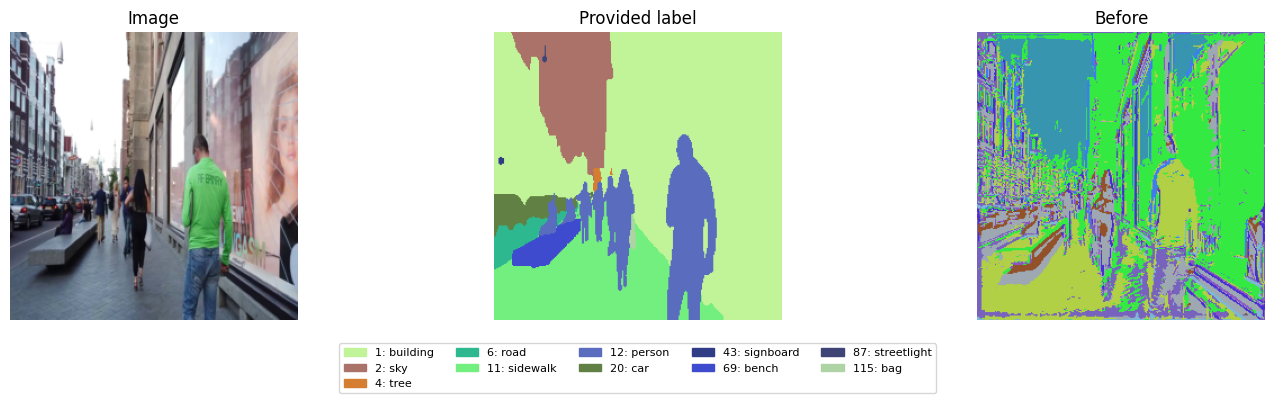

In [11]:
for i in range(min(3, len(ds))):
    sample = ds[i]
    show_segmentation(sample["image"], segment(sample["image"]), ground_truth(sample), title="Before")

---
## 6-1. 전이학습(Transfer Learning)의 개념

```
사전학습 BiRefNet (Swin-L 특징 추출기 + decoder)
        ↓ 마지막 Conv2d만 1 → 150채널로 교체
150개 클래스별 픽셀 logits
        ↓ 학습 전 평가 (Before)
같은 모델을 WT-Sem으로 파인튜닝
        ↓ 학습 후 평가 (After)
같은 test 이미지의 mIoU와 마스크 비교
```

마지막 층은 새로 초기화하지만 나머지는 사전학습 가중치를 재사용합니다.
파인튜닝에서는 특징 추출기와 decoder를 포함해 전체 모델을 업데이트합니다.

In [12]:
print("교체 전 출력 채널:", original_out_channels)
print("교체 후 출력층:", model.network.decoder.conv_out1[0])
print("전체 파라미터 수:", f"{sum(p.numel() for p in model.parameters()):,}")
print("학습 가능한 파라미터 수:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

교체 전 출력 채널: 1
교체 후 출력층: Conv2d(240, 150, kernel_size=(1, 1), stride=(1, 1))
전체 파라미터 수: 220,212,407
학습 가능한 파라미터 수: 220,212,407


학습 전후의 출발점을 맞추기 위해 모델이나 출력층을 다시 만들지 않습니다.
원래 BiRefNet의 이진 보조 출력과 경계 attention은 구조를 유지합니다.
이번 의미 분할 실습에서는 **마지막 150채널 출력의 cross entropy만** loss로 사용합니다.
BiRefNet 원 논문의 이진 분할용 여러 보조 loss를 그대로 재현하는 실험은 아닙니다.

---
## 6-2. 전이학습 실습 — `Trainer`로 파인튜닝하기

학습 512장 / 검증 128장 / 평가 128장, 3 epoch, learning rate `5e-5`를 사용합니다.
Colab 메모리를 고려해 입력은 256×256, 실제 배치는 2, gradient accumulation은 8로 설정합니다.
일반적인 update의 유효 배치는 16입니다. epoch 끝의 남은 배치는 더 작을 수 있습니다.
이 모델에는 BatchNorm이 있어 실제 학습 배치 1로 줄이지 않습니다.

train·validation으로 학습과 checkpoint를 선택하고, test는 전후 비교에만 사용합니다.
FP16에서의 불안정성을 피하기 위해 FP32로 시작합니다.

In [13]:
# 1번 설치 셀에서 Trainer까지 필요한 라이브러리를 설치했습니다.
from transformers import Trainer, TrainingArguments
print("Trainer 준비 완료")

Trainer 준비 완료


### ① 데이터셋과 전처리기 준비

- **학습**: 저장소 train의 10개 영상에서 51~52장씩 = 512장 (2⁹)
- **검증**: 저장소 val의 Poznan에서 128장 (2⁷)
- **평가**: 저장소 val의 Rome·Torun에서 각각 64장 = 128장 (2⁷)

별도 test가 없어 원래 val 영상을 검증·평가로 나눕니다. 세 split 사이에는 같은 영상이 없습니다.
서로 다른 시점에서 고르지만 작은 표본과 도시 차이, 드문 클래스 때문에 점수는 변동할 수 있습니다.
이미지는 bilinear, 라벨은 nearest로 256×256 리사이즈합니다.
이 해상도에서는 작은 사람이나 얇은 경계가 손실될 수 있으므로 원래 해상도 성능으로 해석하지 않습니다.

In [14]:
NUM_TRAIN, NUM_VAL, NUM_TEST = 512, 128, 128
assert NUM_TRAIN >= len(TRAIN_CITIES) and NUM_TEST % 2 == 0
per_city, remainder = divmod(NUM_TRAIN, len(TRAIN_CITIES))
train_city_counts = {city: per_city + int(i < remainder) for i, city in enumerate(TRAIN_CITIES)}
raw_ds = DatasetDict({
    "train": concatenate_datasets([
        load_city("train", city, train_city_counts[city]) for city in TRAIN_CITIES
    ]).shuffle(seed=SEED),
    "validation": load_city("val", "Poznan", NUM_VAL),
    "test": concatenate_datasets([
        load_city("val", city, NUM_TEST // 2) for city in ["Rome", "Torun"]
    ]),
})
assert [len(raw_ds[split]) for split in ["train", "validation", "test"]] == [NUM_TRAIN, NUM_VAL, NUM_TEST]
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert set(raw_ds[a]["city"]).isdisjoint(raw_ds[b]["city"])
    assert set(raw_ds[a]["sample_id"]).isdisjoint(raw_ds[b]["sample_id"])

def transform_batch(batch):
    return {
        "pixel_values": [image_transform(im.convert("RGB")) for im in batch["image"]],
        "labels": [torch.from_numpy(ground_truth({"mask": m}).copy()) for m in batch["mask"]],
    }

ds = DatasetDict({split: subset.with_transform(transform_batch) for split, subset in raw_ds.items()})
print(raw_ds)
# 학습셋의 픽셀 분포만 확인합니다. 검증·평가 분포를 보고 학습 설정을 맞추지 않습니다.
train_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
for sample in tqdm(raw_ds["train"], desc="학습 클래스 분포"):
    mask = ground_truth(sample)
    valid = mask != IGNORE_INDEX
    train_counts += np.bincount(mask[valid], minlength=NUM_CLASSES)
print("학습셋에 나타나는 클래스 수:", int((train_counts > 0).sum()), "/", NUM_CLASSES)
top = np.argsort(train_counts)[-10:][::-1]
print("픽셀 수 상위 10개:", [(id2label[int(i)], int(train_counts[i])) for i in top])

train/Amsterdam:   0%|          | 0/52 [00:00<?, ?it/s]

train/Bangkok:   0%|          | 0/52 [00:00<?, ?it/s]

train/Chiang_Mai:   0%|          | 0/51 [00:00<?, ?it/s]

train/Istanbul:   0%|          | 0/51 [00:00<?, ?it/s]

train/Kuala_Lampur:   0%|          | 0/51 [00:00<?, ?it/s]

...

val/Rome:   0%|          | 0/64 [00:00<?, ?it/s]

val/Torun:   0%|          | 0/64 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'city', 'frame_id', 'sample_id'],
        num_rows: 512
    })
    validation: Dataset({
        features: ['image', 'mask', 'city', 'frame_id', 'sample_id'],
        num_rows: 128
    })
    test: Dataset({
        features: ['image', 'mask', 'city', 'frame_id', 'sample_id'],
        num_rows: 128
    })
})


학습 클래스 분포:   0%|          | 0/512 [00:00<?, ?it/s]

학습셋에 나타나는 클래스 수: 97 / 150
픽셀 수 상위 10개: [('building', 11802215), ('tree', 4231225), ('sky', 3493524), ('sidewalk', 2612540), ('road', 1831941), ('person', 1726229), ('wall', 1324688), ('earth', 847447), ('animal', 738681), ('car', 608701)]


### ② 배치 묶기(collator)와 평가지표

`pixel_values`는 `[B, 3, H, W]`, 정수 `labels`는 `[B, H, W]`입니다.
주 지표 **mIoU**는 클래스별 픽셀 영역의 교집합/합집합을 평균합니다.
큰 도로·건물이 pixel accuracy를 지배할 수 있어 mIoU를 함께 봅니다.

전체 평가셋의 혼동행렬을 먼저 합친 뒤 계산합니다. 정답 또는 예측에 나타난 클래스(합집합 > 0)를
mIoU·mDice 평균에 포함하므로, 정답에 없는 클래스를 잘못 예측해도 반영됩니다.
정답·예측 모두에 없는 클래스는 평균에서 제외합니다. Before·After의 유효 클래스 수도 표시합니다.

In [15]:
def collate_fn(batch):
    return {"pixel_values": torch.stack([x["pixel_values"] for x in batch]),
            "labels": torch.stack([x["labels"] for x in batch]).long()}

def preprocess_logits_for_metrics(logits, labels):
    if isinstance(logits, (tuple, list)):
        logits = logits[0]
    # 150채널 실수 logits 전체를 저장하지 않아 평가 메모리를 줄입니다.
    return logits.argmax(dim=1).to(torch.uint8)

def compute_metrics(eval_pred):
    pred, target = eval_pred
    pred, target = np.asarray(pred).astype(np.int64), np.asarray(target).astype(np.int64)
    valid = (target != IGNORE_INDEX) & (target != -100)  # 분산 수집 padding도 제외
    target, pred = target[valid], pred[valid]
    if not len(target):
        raise ValueError("평가 가능한 정답 픽셀이 없습니다.")
    if np.any((target < 0) | (target >= NUM_CLASSES) | (pred < 0) | (pred >= NUM_CLASSES)):
        raise ValueError("평가 클래스 ID 범위를 확인하세요.")
    confusion = np.bincount(NUM_CLASSES*target + pred, minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES)
    intersection = np.diag(confusion).astype(float)
    gt_area, pred_area = confusion.sum(axis=1), confusion.sum(axis=0)
    union = gt_area + pred_area - intersection
    active = union > 0
    return {
        "miou": float(np.mean(intersection[active] / union[active])),
        "mdice": float(np.mean(2*intersection[active] / (gt_area+pred_area)[active])),
        "pixel_accuracy": float(intersection.sum() / gt_area.sum()),
        "mean_accuracy": float(np.mean(intersection[gt_area > 0] / gt_area[gt_area > 0])),
        "evaluated_classes": int(active.sum()),
    }

### ③ 사전학습 모델 준비 (교체한 출력층 유지)

첫 추론에서 만든 150클래스 모델을 그대로 `Trainer`에 연결합니다.
Before 측정 후 그 모델에 `train()`을 적용합니다.

In [16]:
assert model.network.decoder.conv_out1[0].out_channels == NUM_CLASSES
assert all(p.requires_grad for p in model.network.bb.parameters())
model.config.id2label = id2label
model.config.label2id = label2id
print("첫 추론과 동일한 가중치로 학습 전 평가를 시작합니다.")

첫 추론과 동일한 가중치로 학습 전 평가를 시작합니다.


### ④ 학습 설정 & 실행

같은 test의 학습 전 지표와 첫 3장 예측을 기록한 뒤 학습합니다.
검증과 저장은 epoch마다 수행하고, 검증 loss가 가장 작은 checkpoint를 마지막에 불러옵니다.
학습 loss도 epoch마다 기록하므로 **1·2·3 epoch의 값**을 검증 곡선과 나란히 볼 수 있습니다.

In [17]:
training_args = TrainingArguments(
    output_dir="./birefnet-walking-tours",
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    num_train_epochs=3,
    learning_rate=5e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=1,
    remove_unused_columns=False,
    label_names=["labels"],
    fp16=False,
    bf16=False,
    dataloader_drop_last=True,  # BatchNorm을 위해 train의 1장짜리 마지막 배치 방지
    dataloader_num_workers=0,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
)
# 현 설정은 세 split이 모두 짝수이므로 drop_last로 빠지는 평가 이미지가 없습니다.
assert all(len(ds[split]) % 2 == 0 for split in ds)
trainer = Trainer(
    model=model, args=training_args,
    train_dataset=ds["train"], eval_dataset=ds["validation"],
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    preprocess_logits_for_metrics=preprocess_logits_for_metrics,
)
before_metrics = trainer.evaluate(ds["test"], metric_key_prefix="before")
before_predictions = [segment(raw_ds["test"][i]["image"], trainer.model, original_size=False)
                      for i in range(3)]
print("Before:", before_metrics)
train_result = trainer.train()
print("검증 loss 기준 선택 checkpoint:", trainer.state.best_model_checkpoint)

Before: {'before_loss': 5.052684783935547, 'before_model_preparation_time': 0.0106, 'before_miou': 0.0004177133099335661, 'before_mdice': 0.0008086173039522943, 'before_pixel_accuracy': 0.005779743194580078, 'before_mean_accuracy': 0.0024144938862985096, 'before_evaluated_classes': 100, 'before_runtime': 13.5179, 'before_samples_per_second': 9.469, 'before_steps_per_second': 4.734}


Epoch,Training Loss,Validation Loss,Model Preparation Time,Miou,Mdice,Pixel Accuracy,Mean Accuracy,Evaluated Classes
1,4.739800,4.502213,0.010600,0.008637,0.012143,0.483949,0.028988,143
2,3.806700,3.817258,0.010600,0.011147,0.015269,0.559250,0.038835,145
3,3.305900,2.938567,0.010600,0.014413,0.018849,0.582136,0.045316,130


검증 loss 기준 선택 checkpoint: ./birefnet-walking-tours/checkpoint-96


### ⑤ 최종 성능 확인 & 파인튜닝 모델로 추론

같은 test 이미지·마스크·해상도·평가 함수로 After를 측정합니다.
표의 지표는 0~1 범위이며 높을수록 좋습니다. 성능 향상을 미리 가정하지 않고 실제 결과를 비교합니다.

In [18]:
import pandas as pd

after_metrics = trainer.evaluate(ds["test"], metric_key_prefix="after")
metric_names = {"mIoU": "miou", "mDice": "mdice", "Pixel accuracy": "pixel_accuracy",
                "Mean accuracy": "mean_accuracy"}
comparison = pd.DataFrame(
    [{name: metrics[f"{prefix}_{key}"] for name, key in metric_names.items()}
     for prefix, metrics in [("before", before_metrics), ("after", after_metrics)]],
    index=["Before fine-tuning", "After fine-tuning"],
)
comparison.loc["After - Before"] = comparison.iloc[1] - comparison.iloc[0]
display(comparison.round(4))
print("mIoU 평균에 포함된 클래스 수:", before_metrics["before_evaluated_classes"],
      "→", after_metrics["after_evaluated_classes"])

# wrapper 모델을 재사용할 수 있도록 가중치와 실험 설정을 함께 저장합니다.
save_dir = Path(training_args.output_dir) / "final"
trainer.save_model(str(save_dir))
experiment = {
    "base_model": checkpoint, "model_revision": MODEL_REVISION,
    "dataset": dataset_id, "dataset_revision": DATASET_REVISION,
    "image_size": IMAGE_SIZE, "id2label": id2label, "ignore_index": IGNORE_INDEX,
    "loss": "final-output cross_entropy", "seed": SEED,
    "split_cities": {split: sorted(set(subset["city"])) for split, subset in raw_ds.items()},
    "counts": {split: len(subset) for split, subset in raw_ds.items()},
    "before": before_metrics, "after": after_metrics,
}
(save_dir / "experiment.json").write_text(json.dumps(experiment, ensure_ascii=False, indent=2), encoding="utf-8")
print("저장 위치:", save_dir)
# 재로딩: 8번 셀로 동일한 wrapper/150채널 구조를 만든 후
# from safetensors.torch import load_file
# model.load_state_dict(load_file(str(save_dir / "model.safetensors")))

,mIoU,mDice,Pixel accuracy,Mean accuracy
Before fine-tuning,0.0004,0.0008,0.0058,0.0024
After fine-tuning,0.0171,0.0216,0.6839,0.0539
After - Before,0.0167,0.0208,0.6781,0.0515


mIoU 평균에 포함된 클래스 수: 100 → 132
저장 위치: birefnet-walking-tours/final


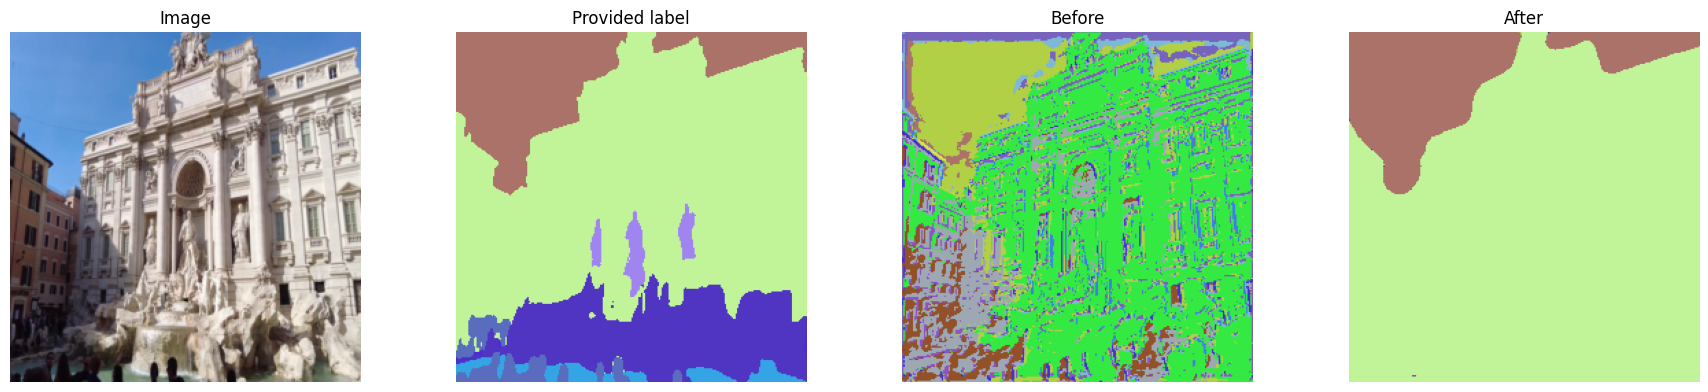

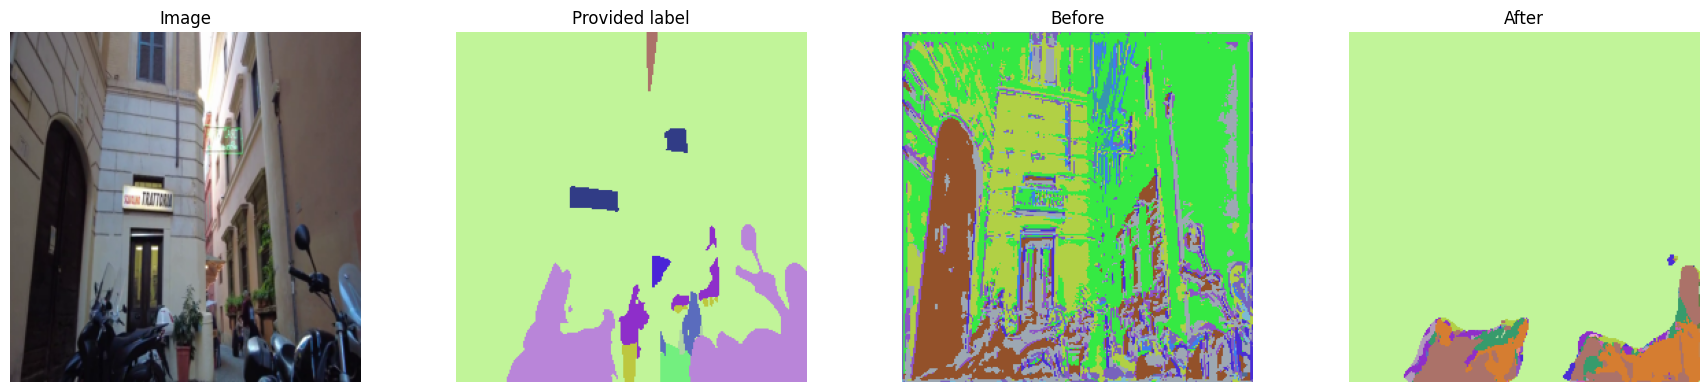

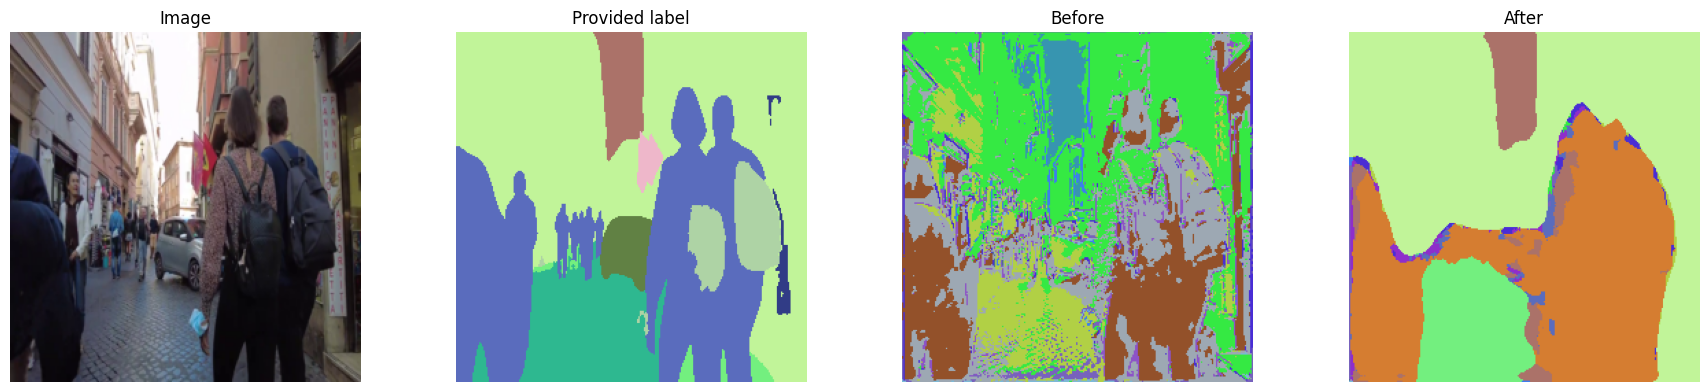

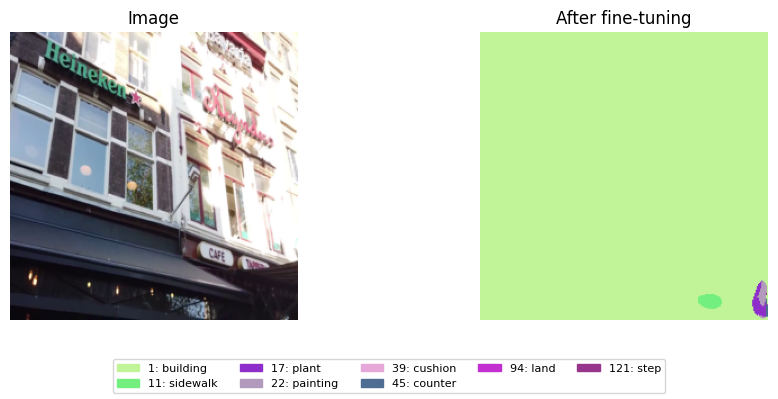

In [19]:
for i in range(3):
    sample = raw_ds["test"][i]
    after_prediction = segment(sample["image"], trainer.model, original_size=False)
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    panels = [("Image", sample["image"]), ("Provided label", color_mask(ground_truth(sample))),
              ("Before", color_mask(before_predictions[i])), ("After", color_mask(after_prediction))]
    for ax, (title, content) in zip(axes, panels):
        ax.imshow(content)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# 4번에서 선택한 내 이미지에도 학습 후 모델을 적용합니다.
show_segmentation(my_image, segment(my_image, trainer.model), title="After fine-tuning")

### ⑥ 학습 곡선 그리기

`trainer.state.log_history`에서 epoch별 학습 loss·검증 loss·검증 mIoU를 그립니다.
학습 전후 test 점수는 모델 선택용 곡선에 섞지 않습니다.

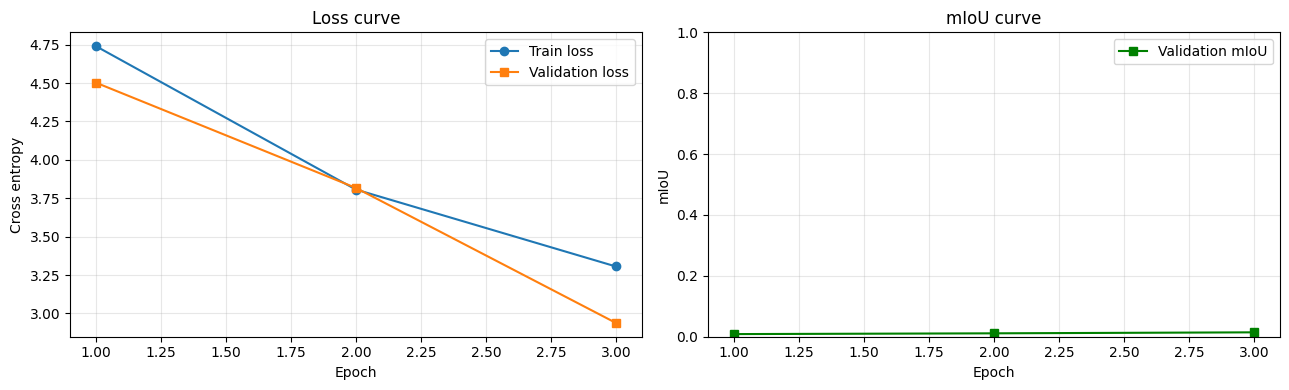

In [20]:
logs = trainer.state.log_history
train_logs = [x for x in logs if "loss" in x and "epoch" in x]
eval_logs = [x for x in logs if "eval_loss" in x and "epoch" in x]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot([x["epoch"] for x in train_logs], [x["loss"] for x in train_logs], "o-", label="Train loss")
axes[0].plot([x["epoch"] for x in eval_logs], [x["eval_loss"] for x in eval_logs], "s-", label="Validation loss")
axes[0].set(title="Loss curve", xlabel="Epoch", ylabel="Cross entropy")
axes[0].legend()
axes[1].plot([x["epoch"] for x in eval_logs], [x["eval_miou"] for x in eval_logs], "s-", color="green", label="Validation mIoU")
axes[1].set(title="mIoU curve", xlabel="Epoch", ylabel="mIoU", ylim=(0, 1))
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**곡선 해석 팁**
- loss는 cross entropy, mIoU는 픽셀 영역의 일치도이므로 변화가 완전히 같지는 않습니다.
- 학습 loss가 내려가도 검증 mIoU가 개선되지 않으면 과적합·도시 차이·희소 클래스 영향을 살펴봅니다.
- 3 epoch·768장의 축소 실습만으로 원래 BiRefNet의 성능이나 충분한 수렴을 단정하지 않습니다.
- 조정은 validation 기준으로 합니다. 먼저 학습 영상별 프레임 수를 늘리고, 검증 곡선을 보고 epoch를 늘립니다.
  최종 test를 반복해서 보고 최적값을 고르지 않습니다.
- 더 높은 해상도는 작은 객체에 유리할 수 있지만 메모리와 시간이 늘어납니다.
  다음 실험에서는 `IMAGE_SIZE=384` 등으로 바꾸고 모델 생성부터 전체를 다시 실행합니다.
- 같은 색이라도 클래스 ID가 맞는지 확인하고, pseudo label 자체가 틀린 예시도 살펴봅니다.

**정리**
- 사전학습 BiRefNet의 마지막 출력층을 150개 클래스용으로 교체했습니다.
- 동일한 초기 모델의 학습 전후를 비교하고, 검증 loss로 선택한 모델을 평가했습니다.
- 영상이 겹치지 않는 split과 같은 평가 해상도로 mIoU·mDice·pixel accuracy를 측정했습니다.
- 제공된 마스크는 OpenSeeD pseudo label이며, 일부 클래스는 축소 표본에 없을 수 있습니다.

---
## 7. 정리

| 단계 | 이번 실습 |
|---|---|
| ① 모델 찾기 | `ZhengPeng7/BiRefNet` |
| ② 불러오기 | 사전학습 모델 + 150채널 새 출력층 |
| ③ 데이터 적용 | WT-Sem 이미지·정수 마스크 ZIP의 프레임 매칭 |
| ④ 파인튜닝 | 같은 모델 전체를 cross entropy로 3 epoch 학습 |
| ⑤ 비교 | 같은 test의 Before/After mIoU와 색상 마스크 |
| ⑥ 기록 | epoch별 학습 loss·검증 loss·검증 mIoU |

**참고 자료**
- [BiRefNet 모델·구현](https://huggingface.co/ZhengPeng7/BiRefNet)
- [WT-Sem 데이터 설명과 구성](https://huggingface.co/datasets/agentic-learning-ai-lab/Walking-Tours-Semantic)
- [ADE20K 150개 클래스 순서](https://huggingface.co/datasets/huggingface/label-files/blob/main/ade20k-id2label.json)
- [OpenSeeD의 0-based 의미 분할 출력 예제](https://github.com/IDEA-Research/OpenSeeD/blob/main/demo/demo_semseg.py)